# Forest fires in Montesinho Natural Park

An exploratory analysis of 517 forest fires in Montesinho Natural Park, in northeastern Portugal: when they happen, how much they burn, what the weather was like, and where in the park they occur.

**Data.** [Forest Fires](https://archive.ics.uci.edu/dataset/162/forest+fires), UCI Machine Learning Repository. Cortez, P. & Morais, A. (2007), licensed under CC BY 4.0. See [`data/README.md`](../data/README.md).

| Column | Meaning |
|---|---|
| `X`, `Y` | position on a 9 × 9 grid over the park map |
| `month`, `day` | month of the year and day of the week |
| `FFMC` | Fine Fuel Moisture Code: dryness of the surface litter |
| `DMC` | Duff Moisture Code: dryness of the shallow organic layers |
| `DC` | Drought Code: dryness of the deep organic layers |
| `ISI` | Initial Spread Index: expected speed at which a fire spreads |
| `temp`, `RH`, `wind`, `rain` | temperature (°C), relative humidity (%), wind (km/h), rain (mm/m²) |
| `area` | burned area in hectares |

FFMC, DMC, DC and ISI come from the Canadian Fire Weather Index system: higher values mean drier fuel and higher fire risk.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
DAYS = ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]

df = pd.read_csv("../data/forestfires.csv")
print(df.shape)
df.head()

(517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


## First look

Check the column types and look for missing values.

In [2]:
df.dtypes

X          int64
Y          int64
month     object
day       object
FFMC     float64
DMC      float64
DC       float64
ISI      float64
temp     float64
RH         int64
wind     float64
rain     float64
area     float64
dtype: object

In [3]:
df.isna().sum().sum()

np.int64(0)

There are no missing values. `month` and `day` are text, so pandas would sort them alphabetically (apr, aug, dec, ...). Turning them into ordered categories makes every table and chart follow the calendar.

In [4]:
df["month"] = pd.Categorical(df["month"], categories=MONTHS, ordered=True)
df["day"] = pd.Categorical(df["day"], categories=DAYS, ordered=True)

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
X,517.0,4.67,2.31,1.0,3.0,4.00,7.00,9.00
Y,517.0,4.30,1.23,2.0,4.0,4.00,5.00,9.00
FFMC,517.0,90.64,5.52,18.7,90.2,91.60,92.90,96.20
DMC,517.0,110.87,64.05,1.1,68.6,108.30,142.40,291.30
DC,517.0,547.94,248.07,7.9,437.7,664.20,713.90,860.60
ISI,517.0,9.02,4.56,0.0,6.5,8.40,10.80,56.10
temp,517.0,18.89,5.81,2.2,15.5,19.30,22.80,33.30
RH,517.0,44.29,16.32,15.0,33.0,42.00,53.00,100.00
wind,517.0,4.02,1.79,0.4,2.7,4.00,4.90,9.40
rain,517.0,0.02,0.30,0.0,0.0,0.00,0.00,6.40


- **Burned area** is the striking column: the median fire burned 0.52 ha and three quarters burned less than 6.6 ha, but the largest burned 1,090 ha. The mean (12.85 ha) is far above the median.
- **Rain** is almost always 0: only 8 of the 517 records have any.
- **FFMC** sits between 90 and 93 for half the fires, close to its maximum: the surface litter was very dry. Its minimum, 18.7, is far below the rest.
- **ISI** has a similar outlier: a maximum of 56.1 against a 75th percentile of 10.8.

## When do fires happen?

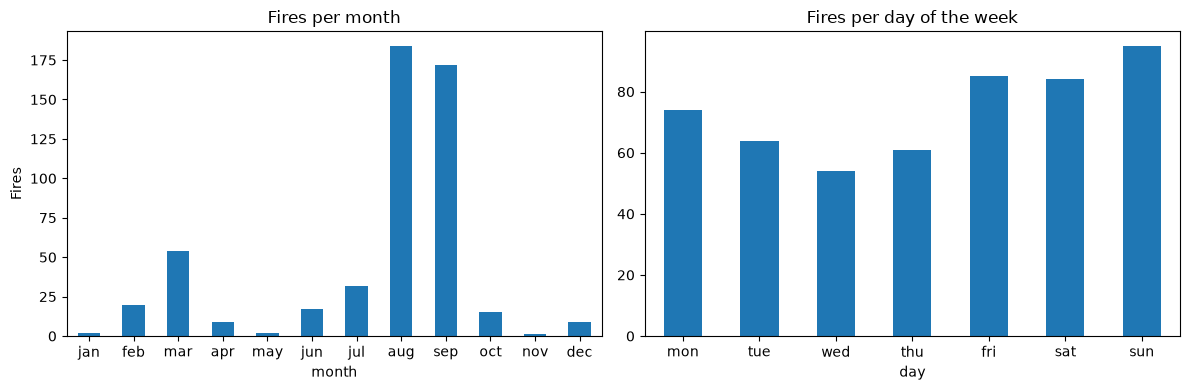

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
df["month"].value_counts(sort=False).plot(kind="bar", ax=left, rot=0, title="Fires per month")
df["day"].value_counts(sort=False).plot(kind="bar", ax=right, rot=0, title="Fires per day of the week")
left.set_ylabel("Fires")
plt.tight_layout()
plt.show()

In [7]:
by_month = df.groupby("month", observed=False).agg(
    fires=("area", "size"),
    burned_ha=("area", "sum"),
    mean_temp=("temp", "mean"),
    mean_RH=("RH", "mean"),
    mean_DC=("DC", "mean"),
)
by_month["share_of_burned_area"] = by_month["burned_ha"] / by_month["burned_ha"].sum()
by_month.round(2)

,fires,burned_ha,mean_temp,mean_RH,mean_DC,share_of_burned_area
month,,,,,,
jan,2,0.00,5.25,89.00,90.35,0.00
feb,20,125.50,9.64,55.70,54.67,0.02
mar,54,235.26,13.08,40.00,75.94,0.04
apr,9,80.02,12.04,46.89,48.56,0.01
may,2,38.48,14.65,67.00,93.75,0.01
jun,17,99.30,20.49,45.12,297.71,0.01
jul,32,459.83,22.11,45.12,450.60,0.07
aug,184,2297.99,21.63,45.49,641.08,0.35
sep,172,3086.13,19.61,42.84,734.62,0.46


Fires are a late-summer problem. August and September have 356 of the 517 fires (69%) and 81% of the burned area. They are not the hottest months (July is, at 22.1 °C on average), but they have the highest Drought Code: after a whole summer without rain, the deep organic layers are at their driest.

March is a smaller second peak, with 54 fires despite a mean temperature of 13 °C. The days of the week are much more even: Sunday has the most fires (95) and Wednesday the fewest (54), possibly because there are more people in the park on weekends.

## How much do fires burn?

In [8]:
zero = (df["area"] == 0).sum()
print(f"{zero} of {len(df)} fires ({zero / len(df):.0%}) are recorded as 0.00 ha")
print(f"skewness of area: {df['area'].skew():.2f}")
print(f"the 10 largest fires account for {df['area'].nlargest(10).sum() / df['area'].sum():.0%} of the burned area")

247 of 517 fires (48%) are recorded as 0.00 ha
skewness of area: 12.85
the 10 largest fires account for 50% of the burned area


Almost half the fires burned less than the smallest unit the dataset records (0.01 ha), and the ten largest burned half of the total. A skewness of 12.85 means the distribution has a very long right tail: a histogram of the raw area is one tall bar at 0 and a few isolated bars far to the right.

The dataset's authors model the logarithm of the area, `ln(area + 1)`. Adding 1 keeps the zeros at 0, and the logarithm pulls the large fires closer to the rest.

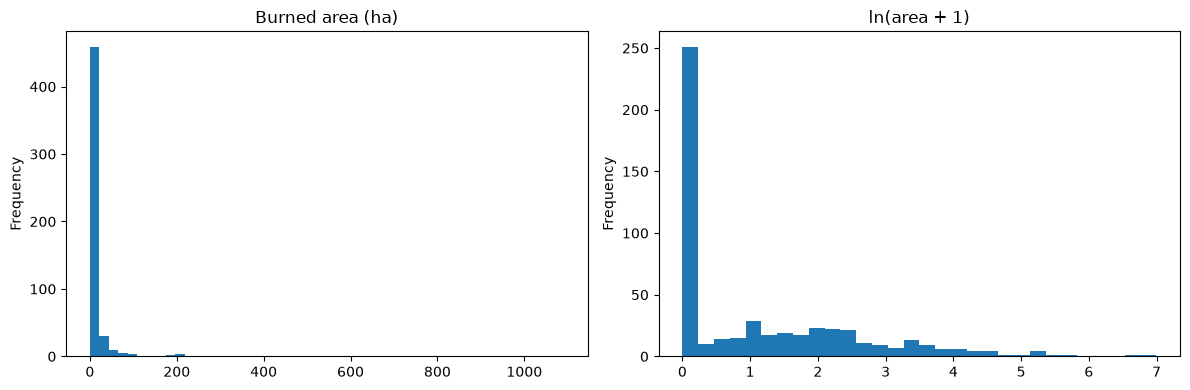

skewness of ln(area + 1): 1.22


In [9]:
df["log_area"] = np.log1p(df["area"])

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
df["area"].plot(kind="hist", bins=50, ax=left, title="Burned area (ha)")
df["log_area"].plot(kind="hist", bins=30, ax=right, title="ln(area + 1)")
plt.tight_layout()
plt.show()

print(f"skewness of ln(area + 1): {df['log_area'].skew():.2f}")

## Weather and fuel dryness

The correlation matrix shows how the numeric variables move together. Values near 1 or −1 mean a strong linear relationship; values near 0, none.

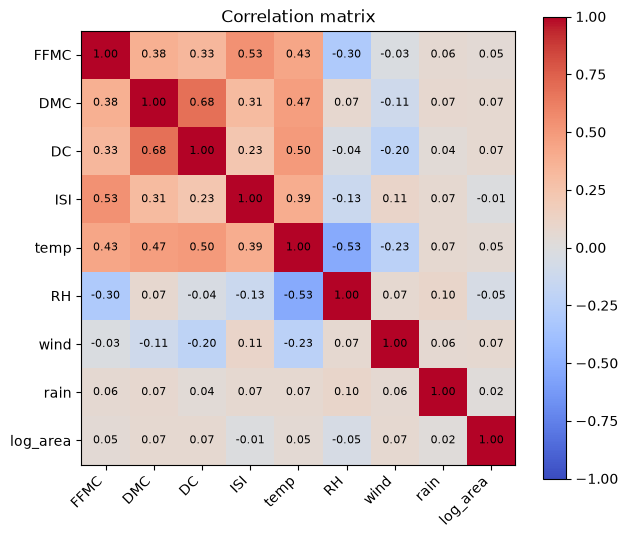

In [10]:
cols = ["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain", "log_area"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation matrix")
plt.show()

- The fire-weather indexes move together, as their definitions suggest: DMC and DC have a correlation of 0.68, and FFMC and ISI of 0.53.
- Hotter days are drier: temperature and humidity have a correlation of −0.53.
- The burned area is almost unrelated to everything else: no variable reaches 0.07 in absolute value with `ln(area + 1)`. Weather tells you when fires are likely, but not how large a given fire will get. The dataset's authors reached a similar conclusion: their best model only predicts the small fires well.

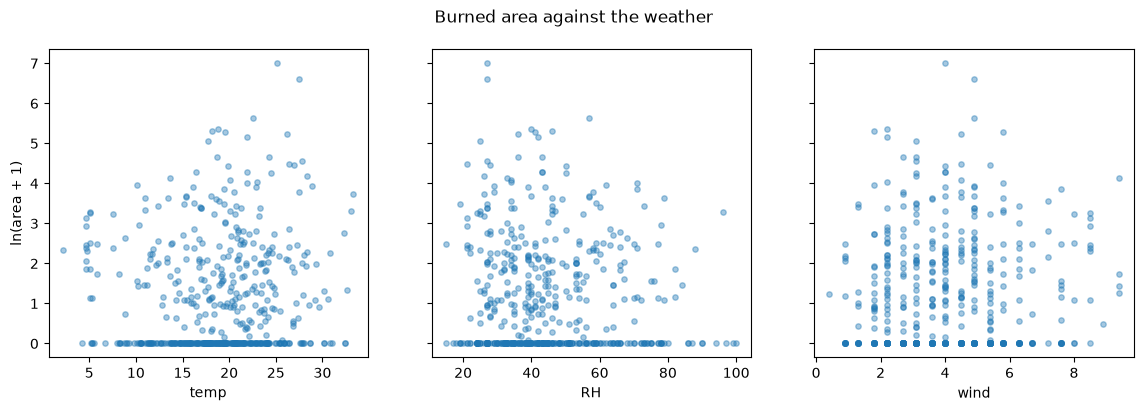

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ["temp", "RH", "wind"]):
    ax.scatter(df[col], df["log_area"], alpha=0.4, s=15)
    ax.set_xlabel(col)
axes[0].set_ylabel("ln(area + 1)")
fig.suptitle("Burned area against the weather")
plt.show()

The scatter plots show the same thing: large and small fires happen across the whole range of temperature, humidity and wind.

## Where in the park?

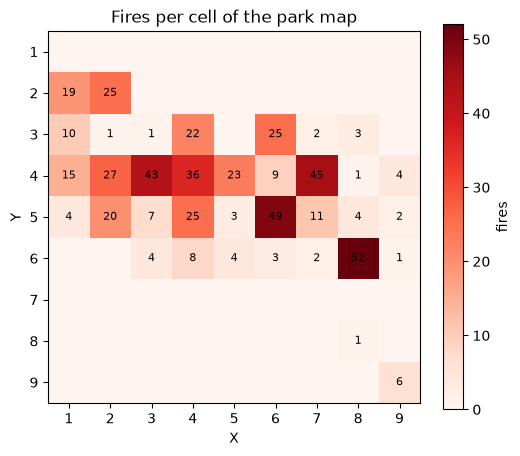

In [12]:
grid = df.pivot_table(index="Y", columns="X", values="area", aggfunc="size", fill_value=0)
grid = grid.reindex(index=range(1, 10), columns=range(1, 10), fill_value=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(grid, cmap="Reds")
ax.set_xticks(range(9), range(1, 10))
ax.set_yticks(range(9), range(1, 10))
ax.set_xlabel("X")
ax.set_ylabel("Y")
for i in range(9):
    for j in range(9):
        if grid.iloc[i, j]:
            ax.text(j, i, grid.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im, label="fires")
ax.set_title("Fires per cell of the park map")
plt.show()

Fires happened in 36 cells of the grid, and a few concentrate many of them: cell (8, 6) has 52 fires, (6, 5) has 49 and (7, 4) has 45. Most fires sit between rows 2 and 6.

## Summary

- Fires concentrate in August and September, when the Drought Code peaks after the summer, rather than in the hottest month.
- The burned area is extremely skewed: half the fires burn almost nothing and ten fires account for half the total. Its logarithm is the scale to work with.
- The fire-weather indexes and the weather are strongly related to each other but barely related to the size of a fire.
- Fires cluster in a few cells of the park.

## pandas methods used

| Step | Method |
|---|---|
| Calendar order for text columns | `pd.Categorical(..., ordered=True)` |
| Summary of every numeric column | `describe()` |
| Counts per category | `value_counts(sort=False)` |
| Several statistics per group | `groupby(...).agg(name=(column, function))` |
| Log transform | `np.log1p` |
| Correlations | `corr()` |
| Two-way count table | `pivot_table(..., aggfunc="size")` |